In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_lter.csv
/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_size.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [3]:
df = pd.read_csv(
    "/kaggle/input/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data/penguins_size.csv"
)

df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [4]:
features = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

target = "species"

df_clean = df[features + [target]].copy()

df_clean.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species
0,39.1,18.7,181.0,3750.0,Adelie
1,39.5,17.4,186.0,3800.0,Adelie
2,40.3,18.0,195.0,3250.0,Adelie
3,NaN,NaN,NaN,NaN,Adelie
4,36.7,19.3,193.0,3450.0,Adelie


In [5]:
features = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

target = "species"

df_clean = df[features + [target]].copy()

df_clean.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species
0,39.1,18.7,181.0,3750.0,Adelie
1,39.5,17.4,186.0,3800.0,Adelie
2,40.3,18.0,195.0,3250.0,Adelie
3,NaN,NaN,NaN,NaN,Adelie
4,36.7,19.3,193.0,3450.0,Adelie


In [6]:
le = LabelEncoder()

df_clean["species"] = le.fit_transform(df_clean["species"])

print("Classes:", le.classes_)
print(df_clean["species"].value_counts())

Classes: ['Adelie' 'Chinstrap' 'Gentoo']
species
0    152
2    124
1     68
Name: count, dtype: int64


In [7]:
X = df_clean[features].values
y = df_clean["species"].values

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (344, 4)
y Shape: (344,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (275, 4)
X_test: (69, 4)
y_train: (275,)
y_test: (69,)


In [9]:

# Handle missing values using training data medians only

train_medians = np.nanmedian(X_train, axis=0)

X_train = np.where(np.isnan(X_train), train_medians, X_train)
X_test = np.where(np.isnan(X_test), train_medians, X_test)

print("Missing values in X_train:", np.isnan(X_train).sum())
print("Missing values in X_test:", np.isnan(X_test).sum())


Missing values in X_train: 0
Missing values in X_test: 0


In [10]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Mean:", X_train.mean(axis=0))
print("Training Std:", X_train.std(axis=0))

Training Mean: [-2.77030923e-15  5.63428092e-15  3.73438654e-16  1.00929366e-16]
Training Std: [1. 1. 1. 1.]


In [11]:
def rbf_kernel(X1, X2, gamma=0.25):
    X1_sq = np.sum(X1**2, axis=1).reshape(-1, 1)
    X2_sq = np.sum(X2**2, axis=1).reshape(1, -1)

    distances = X1_sq + X2_sq - 2 * X1 @ X2.T
    distances = np.maximum(distances, 0)

    return np.exp(-gamma * distances)

In [12]:
gamma = 1 / X_train.shape[1]

K_train = rbf_kernel(X_train, X_train, gamma)
K_test = rbf_kernel(X_test, X_train, gamma)

print("K_train Shape:", K_train.shape)
print("K_test Shape:", K_test.shape)

K_train Shape: (275, 275)
K_test Shape: (69, 275)


In [13]:
classes = np.unique(y_train)

Y_train = np.where(
    y_train.reshape(-1, 1) == classes.reshape(1, -1),
    1,
    -1
)

print("Classes:", classes)
print("Y_train Shape:", Y_train.shape)
print("Unique Values:", np.unique(Y_train))
print("First 5 Rows:\n", Y_train[:5])

Classes: [0 1 2]
Y_train Shape: (275, 3)
Unique Values: [-1  1]
First 5 Rows:
 [[ 1 -1 -1]
 [ 1 -1 -1]
 [ 1 -1 -1]
 [-1 -1  1]
 [-1 -1  1]]


In [14]:
def predict_scores(K, alpha, bias):
    return K @ alpha + bias


def calculate_loss(K, Y, alpha, bias, lambda_reg):
    scores = predict_scores(K, alpha, bias)

    margins = 1 - Y * scores
    hinge_loss = np.maximum(0, margins).mean()

    regularization = 0.5 * lambda_reg * np.sum(
        alpha * (K @ alpha)
    )

    total_loss = hinge_loss + regularization

    return total_loss

In [15]:
learning_rate = 0.0001
epochs = 200
lambda_reg = 0.01
momentum = 0.9

n_samples = K_train.shape[0]
n_classes = Y_train.shape[1]

alpha = np.zeros((n_samples, n_classes))
bias = np.zeros(n_classes)

velocity_alpha = np.zeros_like(alpha)
velocity_bias = np.zeros_like(bias)

loss_history = []

rng = np.random.default_rng(42)

print("Alpha Shape:", alpha.shape)
print("Bias Shape:", bias.shape)
print("Learning Rate:", learning_rate)
print("Momentum:", momentum)
print("Epochs:", epochs)

Alpha Shape: (275, 3)
Bias Shape: (3,)
Learning Rate: 0.0001
Momentum: 0.9
Epochs: 200


In [16]:
for epoch in range(epochs):

    indices = rng.permutation(n_samples)

    for i in indices:

        K_i = K_train[i:i+1]
        Y_i = Y_train[i:i+1]

        scores = K_i @ alpha + bias

        margins = 1 - Y_i * scores
        active = (margins > 0).astype(float)

        grad_alpha = -(K_i.T @ (Y_i * active)) / Y_i.size
        grad_alpha += lambda_reg * (K_train @ alpha)

        grad_bias = -(Y_i * active).sum(axis=0) / Y_i.size

        velocity_alpha = momentum * velocity_alpha - learning_rate * grad_alpha
        velocity_bias = momentum * velocity_bias - learning_rate * grad_bias

        alpha += velocity_alpha
        bias += velocity_bias

    loss = calculate_loss(K_train, Y_train, alpha, bias, lambda_reg)
    loss_history.append(loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.6f}")

Epoch 20/200, Loss: 0.194771
Epoch 40/200, Loss: 0.188088
Epoch 60/200, Loss: 0.185344
Epoch 80/200, Loss: 0.182515
Epoch 100/200, Loss: 0.182549
Epoch 120/200, Loss: 0.180631
Epoch 140/200, Loss: 0.180123
Epoch 160/200, Loss: 0.179814
Epoch 180/200, Loss: 0.179617
Epoch 200/200, Loss: 0.179280


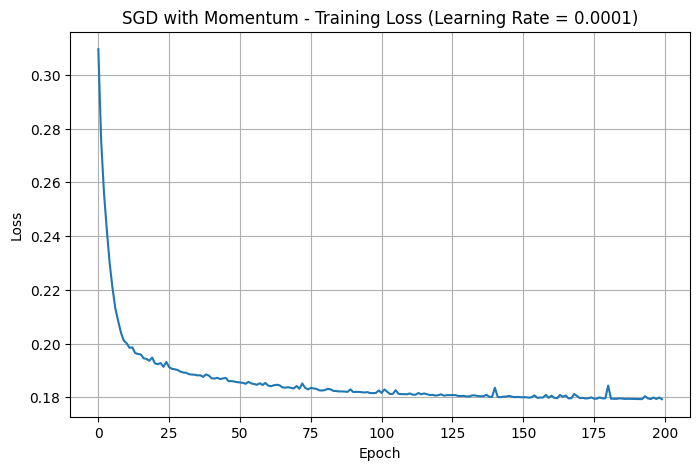

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("SGD with Momentum - Training Loss (Learning Rate = 0.0001)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

In [18]:
test_scores = predict_scores(K_test, alpha, bias)

y_pred = classes[np.argmax(test_scores, axis=1)]

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)
print(f"Test Accuracy (%): {accuracy * 100:.2f}%")

Test Accuracy: 0.9855072463768116
Test Accuracy (%): 98.55%


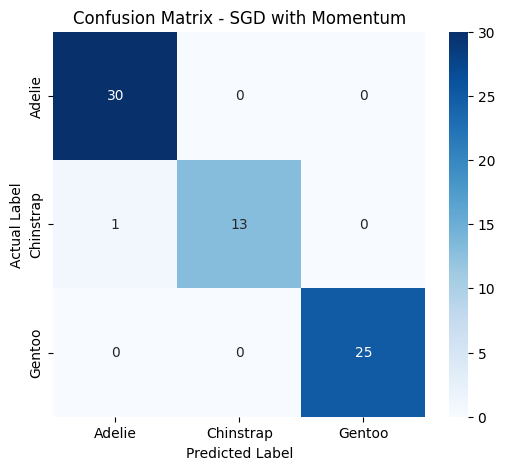

In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - SGD with Momentum")
plt.show()

In [20]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_
))

              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.98        30
   Chinstrap       1.00      0.93      0.96        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.99      0.98      0.98        69
weighted avg       0.99      0.99      0.99        69

